# SDG 11 — Sustainable Cities and Communities
## Analysis of Air Quality in Indian Cities

---

| Item | Detail |
|---|---|
| **Subject** | Data Exploration and Visualization (23CS5PCDEV) |
| **College** | B.M.S. College of Engineering, Bangalore |
| **Dataset** | Indian Cities Air Quality — city_day.csv (CPCB) |
| **SDG Goal** | SDG 11: Sustainable Cities & Communities |
| **Target** | 11.6 — Reduce the environmental impact of cities |

---

## About this Notebook

This notebook performs a full Exploratory Data Analysis (EDA) on cleaned air quality data from 26 Indian cities spanning 2015–2020.  
The preprocessing (cleaning, imputation, feature engineering) was done separately in `src/dfmodif.py` and the cleaned CSV is loaded here.

Every visualization in this notebook is also saved as a PNG file in `outputs/graphs/`.

---
# Section 1 — Introduction and Research Questions

## 1.1 SDG 11 Context

**UN Sustainable Development Goal 11** aims to make cities inclusive, safe, resilient, and sustainable by 2030.  
**Target 11.6** specifically calls for reducing the per capita environmental impact of cities, with particular attention to air quality and municipal waste management.

India faces a severe urban air quality crisis. Many Indian cities rank among the most polluted in the world due to rapid urbanization, industrial growth, increasing vehicle traffic, construction dust, and agricultural burning.

The **Air Quality Index (AQI)** is a standardized scale (0–500+) used by India's Central Pollution Control Board (CPCB) to communicate how clean or polluted the air is:

| AQI Range | Category | Health Impact |
|---|---|---|
| 0–50 | Good | Minimal impact |
| 51–100 | Satisfactory | Minor breathing discomfort to sensitive people |
| 101–200 | Moderate | Breathing discomfort to people with lung/heart disease |
| 201–300 | Poor | Breathing discomfort to most people on prolonged exposure |
| 301–400 | Very Poor | Respiratory illness on prolonged exposure |
| 400+ | Severe | Affects healthy people; seriously impacts those with diseases |

## 1.2 Research Questions

This analysis answers the following specific questions:

1. Which Indian city has the **highest average AQI** (most polluted)?
2. Which city has the **lowest average AQI** (least polluted)?
3. How has AQI **changed year by year** from 2015 to 2020?
4. Which **months or seasons** are most polluted?
5. What is the **distribution of AQI categories** across all records?
6. Which **pollutants correlate most strongly** with AQI?
7. What is the **relationship between PM2.5 and PM10**?
8. How do **pollutant levels vary across cities**?

---
# Section 2 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# ── Output directory for saving graphs ──
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__'))
PROJECT_ROOT = os.path.dirname(NOTEBOOK_DIR)
GRAPH_DIR    = os.path.join(PROJECT_ROOT, 'outputs', 'graphs')
TABLE_DIR    = os.path.join(PROJECT_ROOT, 'outputs', 'tables')
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# ── Global style settings ──
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi'      : 130,
    'savefig.dpi'     : 150,
    'savefig.bbox'    : 'tight',
    'font.family'     : 'DejaVu Sans',
})

print('Libraries imported successfully.')
print(f'Graphs will be saved to: {GRAPH_DIR}')

Libraries imported successfully.
Graphs will be saved to: C:\Users\omkar\OneDrive\Desktop\DEV AAT\DEV_AAT_SDG11\outputs\graphs


---
# Section 3 — Load Dataset

In [2]:
# Load the cleaned dataset produced by src/dfmodif.py
DATA_PATH = os.path.join(PROJECT_ROOT, 'dataset', 'processed', 'city_day_cleaned.csv')

df = pd.read_csv(DATA_PATH, parse_dates=['Date'])

print(f'Dataset loaded from: {DATA_PATH}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Columns: {df.columns.tolist()}')

Dataset loaded from: C:\Users\omkar\OneDrive\Desktop\DEV AAT\DEV_AAT_SDG11\dataset\processed\city_day_cleaned.csv
Shape: 24,850 rows × 18 columns
Columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'PM2.5_Severity']


In [3]:
print('--- First 5 rows ---')
display(df.head())

print('\n--- Last 5 rows ---')
display(df.tail())

--- First 5 rows ---


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket,Year,Month,PM2.5_Severity
0,Ahmedabad,2015-01-29,83.13,141.54,6.93,28.71,33.72,16.54,6.93,49.52,59.76,0.02,0.00,209.0,Poor,2015,January,Moderately Polluted
1,Ahmedabad,2015-01-30,79.84,141.54,13.85,28.68,41.08,16.54,13.85,48.49,97.07,0.04,0.00,328.0,Very Poor,2015,January,Moderately Polluted
2,Ahmedabad,2015-01-31,94.52,141.54,24.39,32.66,52.61,16.54,24.39,67.39,111.33,0.24,0.01,514.0,Severe,2015,January,Poor
3,Ahmedabad,2015-02-01,135.99,141.54,43.48,42.08,84.57,16.54,43.48,75.23,102.70,0.40,0.04,782.0,Severe,2015,February,Very Poor
4,Ahmedabad,2015-02-02,178.33,141.54,54.56,35.31,72.80,16.54,54.56,55.04,107.38,0.46,0.06,914.0,Severe,2015,February,Very Poor



--- Last 5 rows ---


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket,Year,Month,PM2.5_Severity
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,41.0,Good,2020,June,Good
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,70.0,Satisfactory,2020,June,Good
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,68.0,Satisfactory,2020,June,Good
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,54.0,Satisfactory,2020,June,Good
24849,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,0.00,0.00,50.0,Good,2020,July,Good


---
# Section 4 — Initial Data Exploration

Before any analysis, we confirm the structure, completeness, and basic properties of the loaded dataset.

In [4]:
# Column names, non-null counts, and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24850 entries, 0 to 24849
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   City            24850 non-null  str           
 1   Date            24850 non-null  datetime64[us]
 2   PM2.5           24850 non-null  float64       
 3   PM10            24850 non-null  float64       
 4   NO              24850 non-null  float64       
 5   NO2             24850 non-null  float64       
 6   NOx             24850 non-null  float64       
 7   NH3             24850 non-null  float64       
 8   CO              24850 non-null  float64       
 9   SO2             24850 non-null  float64       
 10  O3              24850 non-null  float64       
 11  Benzene         24850 non-null  float64       
 12  Toluene         24850 non-null  float64       
 13  AQI             24850 non-null  float64       
 14  AQI_Bucket      24850 non-null  str           
 15  Year         

In [5]:
# Missing value check — should be zero after preprocessing
missing = df.isnull().sum()
if missing.sum() == 0:
    print('✓ No missing values in any column.')
else:
    print('Missing values detected:')
    print(missing[missing > 0])

✓ No missing values in any column.


In [6]:
# Key dataset facts
print(f"Unique cities    : {df['City'].nunique()}")
print(f"Cities           : {sorted(df['City'].unique())}")
print(f"Date range       : {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Years covered    : {sorted(df['Year'].unique())}")
print(f"Total records    : {len(df):,}")

print("\nAQI Category Distribution:")
cat_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
counts = df['AQI_Bucket'].value_counts()
for cat in counts.index:
    pct = counts[cat] / len(df) * 100
    print(f"  {cat:<15s}: {counts[cat]:5,}  ({pct:.1f}%)")

Unique cities    : 26
Cities           : ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
Date range       : 2015-01-01 to 2020-07-01
Years covered    : [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]
Total records    : 24,850

AQI Category Distribution:
  Moderate       : 8,829  (35.5%)
  Satisfactory   : 8,224  (33.1%)
  Poor           : 2,781  (11.2%)
  Very Poor      : 2,337  (9.4%)
  Good           : 1,341  (5.4%)
  Severe         : 1,338  (5.4%)


In [7]:
# Categorise columns by data type
numerical_cols   = df.select_dtypes(include=['float64', 'int32', 'int64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical columns   ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Numerical columns   (13): ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'Year']
Categorical columns (4): ['City', 'AQI_Bucket', 'Month', 'PM2.5_Severity']


---
# Section 5 — Statistical Analysis

We calculate descriptive statistics for AQI and all pollutant columns to understand the central tendency, spread, and range of measurements.

In [8]:
# Full statistical summary for numeric columns
key_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
stats = df[key_cols].describe().round(2)
display(stats)

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI
count,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00
mean,68.88,121.75,17.76,28.67,31.73,26.61,2.32,14.50,35.04,166.46
std,64.84,90.56,22.89,24.63,29.99,27.48,7.02,17.83,22.08,140.70
min,0.04,0.03,0.03,0.01,0.00,0.01,0.00,0.01,0.01,13.00
25%,28.90,58.32,5.63,11.71,13.40,9.03,0.58,5.65,19.28,81.00
50%,48.85,97.15,9.93,21.84,23.64,17.00,0.93,9.19,31.12,118.00
75%,82.22,153.97,20.04,37.94,39.08,38.77,1.47,15.28,45.93,208.00
max,914.94,917.08,390.68,362.21,378.24,352.89,175.81,186.08,257.73,2049.00


In [9]:
# Detailed AQI statistics
aqi = df['AQI']
print("AQI — Key Statistics")
print(f"  Mean              : {aqi.mean():.1f}")
print(f"  Median            : {aqi.median():.1f}")
print(f"  Std Deviation     : {aqi.std():.1f}")
print(f"  Min               : {aqi.min():.0f}")
print(f"  Max               : {aqi.max():.0f}")
print(f"  25th Percentile   : {aqi.quantile(0.25):.1f}")
print(f"  75th Percentile   : {aqi.quantile(0.75):.1f}")
print(f"  Skewness          : {aqi.skew():.2f}  (right-skewed = long tail of high values)")
print(f"  Records > 300     : {(aqi > 300).sum():,}  ({(aqi > 300).mean()*100:.1f}%)")
print(f"  Records > 500     : {(aqi > 500).sum():,}  ({(aqi > 500).mean()*100:.1f}%)")

AQI — Key Statistics
  Mean              : 166.5
  Median            : 118.0
  Std Deviation     : 140.7
  Min               : 13
  Max               : 2049
  25th Percentile   : 81.0
  75th Percentile   : 208.0
  Skewness          : 3.40  (right-skewed = long tail of high values)
  Records > 300     : 3,675  (14.8%)
  Records > 500     : 543  (2.2%)


In [10]:
# City-wise AQI statistics
city_stats = df.groupby('City')['AQI'].agg(['mean','median','std','min','max']).round(1)
city_stats.columns = ['Mean AQI', 'Median AQI', 'Std Dev', 'Min', 'Max']
city_stats = city_stats.sort_values('Mean AQI', ascending=False)

print("City-wise AQI Statistics (sorted by mean, most polluted first):")
display(city_stats)

# Save to table
city_stats.to_csv(os.path.join(TABLE_DIR, 'city_aqi_statistics.csv'))
print(f"\nSaved to outputs/tables/city_aqi_statistics.csv")

City-wise AQI Statistics (sorted by mean, most polluted first):


,Mean AQI,Median AQI,Std Dev,Min,Max
City,,,,,
Ahmedabad,452.1,384.5,311.7,48.0,2049.0
Delhi,259.5,257.0,119.5,29.0,716.0
Patna,240.8,215.0,122.3,53.0,619.0
Gurugram,225.1,208.0,119.9,38.0,891.0
Lucknow,218.0,198.0,117.0,39.0,707.0
Talcher,172.9,128.5,104.9,13.0,570.0
Jorapokhar,159.3,133.0,84.7,27.0,604.0
Brajrajnagar,150.3,122.0,70.4,22.0,355.0
Kolkata,140.6,94.0,104.5,26.0,475.0



Saved to outputs/tables/city_aqi_statistics.csv


In [11]:
# Year-wise AQI statistics
year_stats = df.groupby('Year')['AQI'].agg(['mean','median','std','count']).round(1)
year_stats.columns = ['Mean AQI', 'Median AQI', 'Std Dev', 'Record Count']
print("Year-wise AQI Statistics:")
display(year_stats)

Year-wise AQI Statistics:


,Mean AQI,Median AQI,Std Dev,Record Count
Year,,,,
2015,212.5,175.0,133.1,1827
2016,197.2,149.0,130.5,2573
2017,181.5,129.0,141.4,3234
2018,182.7,124.0,171.5,5724
2019,156.5,109.0,135.8,7071
2020,113.5,93.0,83.5,4421


In [12]:
# Skewness of key pollutants
skew_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
skewness = df[skew_cols].skew().round(2).sort_values(ascending=False)
print("Skewness (positive = right-skewed = long tail of high values):")
for col, sk in skewness.items():
    direction = 'right-skewed' if sk > 1 else ('left-skewed' if sk < -1 else 'approx normal')
    print(f"  {col:<8}: {sk:>6.2f}  — {direction}")

Skewness (positive = right-skewed = long tail of high values):
  CO      :   8.70  — right-skewed
  SO2     :   3.90  — right-skewed
  NO      :   3.63  — right-skewed
  AQI     :   3.40  — right-skewed
  NH3     :   3.28  — right-skewed
  PM2.5   :   2.82  — right-skewed
  NO2     :   2.45  — right-skewed
  PM10    :   1.96  — right-skewed
  O3      :   1.38  — right-skewed


---
# Section 6 — Exploratory Data Analysis

We now investigate each research question systematically using computed data.

In [13]:
# Research Question 1 & 2: Most and least polluted cities
city_avg = df.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)

print("Top 5 most polluted cities (highest mean AQI):")
for city, aqi in city_avg.head(5).items():
    print(f"  {city:<20s}: {aqi}")

print("\nTop 5 least polluted cities (lowest mean AQI):")
for city, aqi in city_avg.tail(5).items():
    print(f"  {city:<20s}: {aqi}")

Top 5 most polluted cities (highest mean AQI):
  Ahmedabad           : 452.1
  Delhi               : 259.5
  Patna               : 240.8
  Gurugram            : 225.1
  Lucknow             : 218.0

Top 5 least polluted cities (lowest mean AQI):
  Ernakulam           : 92.4
  Thiruvananthapuram  : 75.9
  Coimbatore          : 73.0
  Shillong            : 53.8
  Aizawl              : 34.8


In [14]:
# Research Question 3: Year-wise trend
year_avg = df.groupby('Year')['AQI'].mean().round(1)
print("Year-wise mean AQI:")
for yr, val in year_avg.items():
    print(f"  {yr}: {val}")

change = year_avg.iloc[-1] - year_avg.iloc[0]
print(f"\nChange from {year_avg.index[0]} to {year_avg.index[-1]}: {change:+.1f} AQI points")

Year-wise mean AQI:
  2015: 212.5
  2016: 197.2
  2017: 181.5
  2018: 182.7
  2019: 156.5
  2020: 113.5

Change from 2015 to 2020: -99.0 AQI points


In [15]:
# Research Question 4: Seasonal patterns
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
month_avg = df.groupby('Month')['AQI'].mean().reindex(month_order).round(1)

print("Monthly mean AQI:")
for month, val in month_avg.items():
    bar = '█' * int(val / 10)
    print(f"  {month:<12s}: {val:>6.1f}  {bar}")

print(f"\nHighest pollution month: {month_avg.idxmax()} ({month_avg.max():.1f})")
print(f"Lowest  pollution month: {month_avg.idxmin()} ({month_avg.min():.1f})")

Monthly mean AQI:
  January     :  231.7  ███████████████████████
  February    :  202.9  ████████████████████
  March       :  164.7  ████████████████
  April       :  143.4  ██████████████
  May         :  135.5  █████████████
  June        :  120.2  ████████████
  July        :  111.9  ███████████
  August      :  113.6  ███████████
  September   :  115.2  ███████████
  October     :  188.6  ██████████████████
  November    :  241.7  ████████████████████████
  December    :  227.1  ██████████████████████

Highest pollution month: November (241.7)
Lowest  pollution month: July (111.9)


In [16]:
# Research Question 6: Pollutant-AQI correlations
corr_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']
aqi_corr = df[corr_cols + ['AQI']].corr()['AQI'].drop('AQI').sort_values(ascending=False).round(3)

print("Pearson correlation with AQI (strongest first):")
for col, corr_val in aqi_corr.items():
    strength = 'Strong' if abs(corr_val) >= 0.6 else ('Moderate' if abs(corr_val) >= 0.3 else 'Weak')
    print(f"  {col:<8}: {corr_val:>6.3f}  ({strength})")

Pearson correlation with AQI (strongest first):
  CO      :  0.678  (Strong)
  PM2.5   :  0.635  (Strong)
  NO2     :  0.533  (Moderate)
  PM10    :  0.514  (Moderate)
  SO2     :  0.486  (Moderate)
  NOx     :  0.465  (Moderate)
  NO      :  0.436  (Moderate)
  O3      :  0.198  (Weak)
  NH3     :  0.106  (Weak)


In [17]:
# Research Question 7: PM2.5 vs PM10 relationship
pm_corr = df['PM2.5'].corr(df['PM10'])
print(f"Pearson correlation between PM2.5 and PM10: {pm_corr:.3f}")
print(f"PM2.5 mean: {df['PM2.5'].mean():.1f} µg/m³  |  PM10 mean: {df['PM10'].mean():.1f} µg/m³")
print(f"PM2.5 / PM10 ratio (mean): {(df['PM2.5'].mean() / df['PM10'].mean()):.2f}")
print(f"  (A ratio near 0.5 suggests PM2.5 contributes about half of coarse particles)")

Pearson correlation between PM2.5 and PM10: 0.594
PM2.5 mean: 68.9 µg/m³  |  PM10 mean: 121.7 µg/m³
PM2.5 / PM10 ratio (mean): 0.57
  (A ratio near 0.5 suggests PM2.5 contributes about half of coarse particles)


---
# Section 7 — Data Visualization

Ten visualizations are produced below.  
Each plot is saved as a PNG to `outputs/graphs/` and displayed inline.

> Each chart is followed by a short interpretation explaining what the visual reveals.

## Visualization 1 — AQI Distribution (Histogram)

**What it shows:** How AQI values are distributed across all 24,850 city-day records.  
The vertical dashed lines mark the official category boundaries.

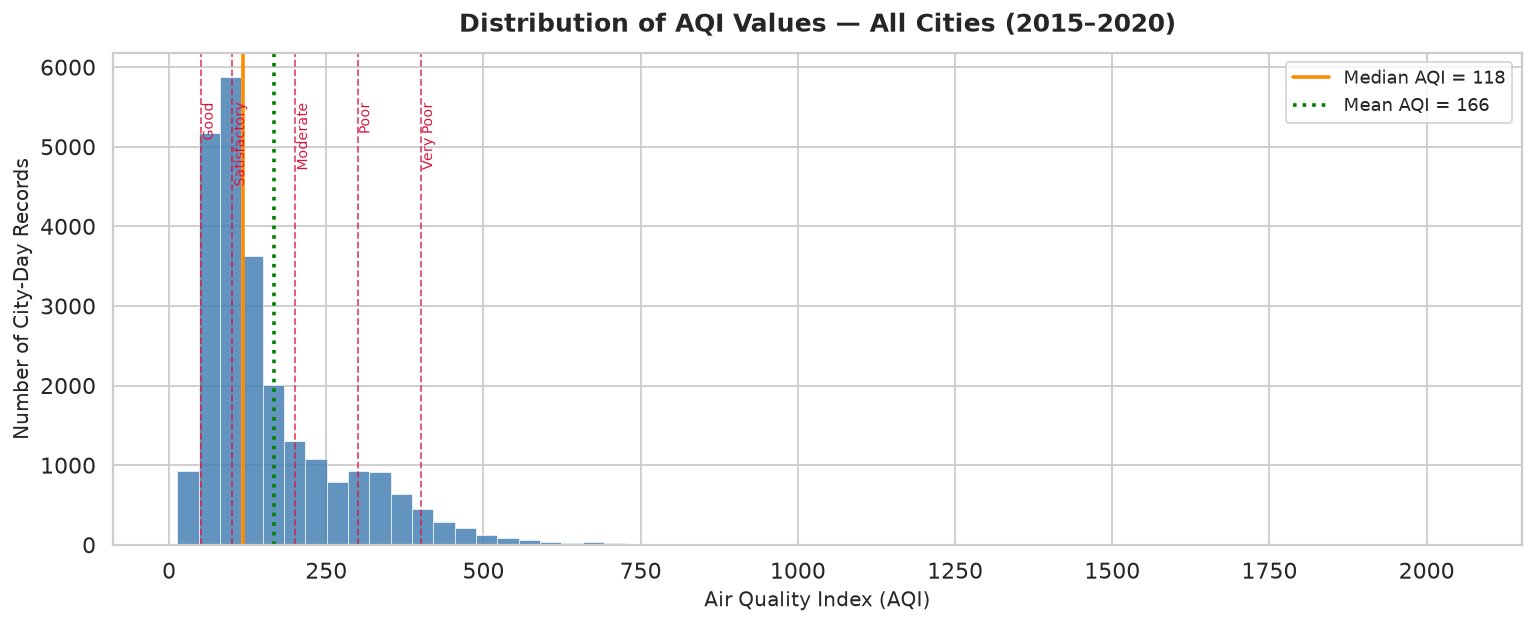

Mean AQI: 166.5 | Median AQI: 118 | Skewness: 3.40
Interpretation: The distribution is strongly right-skewed.
Most city-days fall in the 50–250 range, but a long tail extends past 500,
showing that extreme pollution events occur regularly, not just as rare outliers.


In [18]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(df['AQI'], bins=60, color='steelblue', edgecolor='white', linewidth=0.4, alpha=0.85)

# AQI category boundary lines
boundaries = {50: 'Good', 100: 'Satisfactory', 200: 'Moderate', 300: 'Poor', 400: 'Very Poor'}
for xval, label in boundaries.items():
    ax.axvline(xval, color='crimson', linestyle='--', linewidth=1.0, alpha=0.75)
    ax.text(xval + 2, ax.get_ylim()[1] * 0.90, label,
            fontsize=7.5, color='crimson', rotation=90, va='top')

# Median line
median_aqi = df['AQI'].median()
ax.axvline(median_aqi, color='darkorange', linestyle='-', linewidth=2,
           label=f'Median AQI = {median_aqi:.0f}')

mean_aqi = df['AQI'].mean()
ax.axvline(mean_aqi, color='green', linestyle=':', linewidth=2,
           label=f'Mean AQI = {mean_aqi:.0f}')

ax.set_title('Distribution of AQI Values — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Air Quality Index (AQI)', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_distribution.png'))
plt.show()

print(f"Mean AQI: {mean_aqi:.1f} | Median AQI: {median_aqi:.0f} | Skewness: {df['AQI'].skew():.2f}")
print("Interpretation: The distribution is strongly right-skewed.")
print("Most city-days fall in the 50–250 range, but a long tail extends past 500,")
print("showing that extreme pollution events occur regularly, not just as rare outliers.")

## Visualization 2 — AQI Category Distribution (Bar Chart)

**What it shows:** Count of city-day records per official CPCB AQI category.

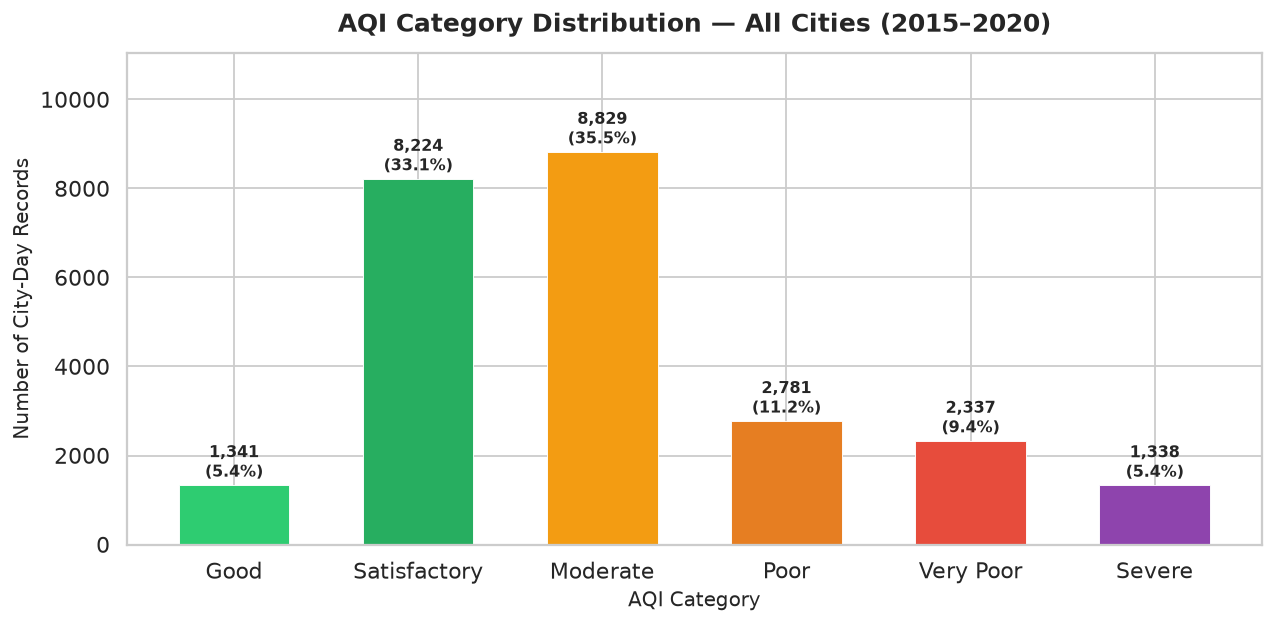

Days with Poor/Very Poor/Severe AQI: 6,456 (26.0%)
Interpretation: 'Moderate' and 'Satisfactory' together account for nearly 70% of all records.
However, 'Poor' + 'Very Poor' + 'Severe' combine to a significant fraction,
confirming that hazardous air quality is a frequent reality, not just an occasional event.


In [19]:
cat_order  = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
cat_colors = ['#2ecc71', '#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#8e44ad']

counts = df['AQI_Bucket'].value_counts().reindex(cat_order)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=cat_colors, edgecolor='white', linewidth=0.5, width=0.6)

for bar in bars:
    h = bar.get_height()
    pct = h / len(df) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 60,
            f'{int(h):,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('AQI Category Distribution — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('AQI Category', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.set_ylim(0, counts.max() * 1.25)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_category_distribution.png'))
plt.show()

poor_days = counts[['Poor','Very Poor','Severe']].sum()
print(f"Days with Poor/Very Poor/Severe AQI: {poor_days:,} ({poor_days/len(df)*100:.1f}%)")
print("Interpretation: 'Moderate' and 'Satisfactory' together account for nearly 70% of all records.")
print("However, 'Poor' + 'Very Poor' + 'Severe' combine to a significant fraction,")
print("confirming that hazardous air quality is a frequent reality, not just an occasional event.")

## Visualization 3 — Top 10 Most Polluted Cities

**What it shows:** Cities ranked by their overall average AQI across 2015–2020.

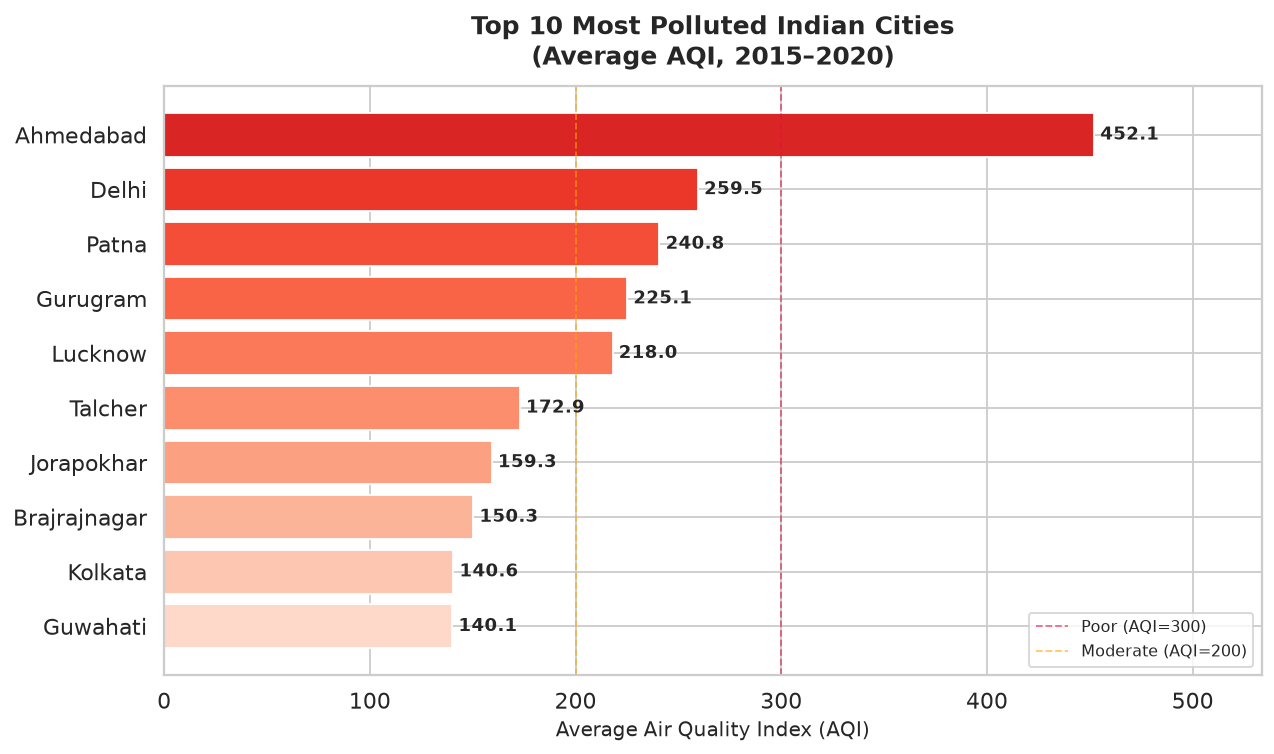

Most polluted city: Ahmedabad (avg AQI 452.1)
Interpretation: The most polluted cities are concentrated in central and northern India.
Most of the top 10 have average AQI values in the 'Poor' category (200–300),
meaning residents face breathing discomfort on a typical day.


In [20]:
city_avg = df.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)
top10 = city_avg.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.Reds_r(np.linspace(0.3, 0.85, len(top10)))
bars = ax.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1], edgecolor='white')

for bar, val in zip(bars, top10.values[::-1]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Top 10 Most Polluted Indian Cities\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average Air Quality Index (AQI)', fontsize=11)
ax.set_xlim(0, top10.max() * 1.18)

# Reference lines
ax.axvline(300, color='crimson', linestyle='--', linewidth=1, alpha=0.6, label='Poor (AQI=300)')
ax.axvline(200, color='orange',  linestyle='--', linewidth=1, alpha=0.6, label='Moderate (AQI=200)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'top_polluted_cities.png'))
plt.show()

print(f"Most polluted city: {city_avg.index[0]} (avg AQI {city_avg.iloc[0]})")
print("Interpretation: The most polluted cities are concentrated in central and northern India.")
print("Most of the top 10 have average AQI values in the 'Poor' category (200–300),")
print("meaning residents face breathing discomfort on a typical day.")

## Visualization 4 — Bottom 10 Least Polluted Cities

**What it shows:** The 10 cities with the lowest average AQI — the cleanest air in the dataset.

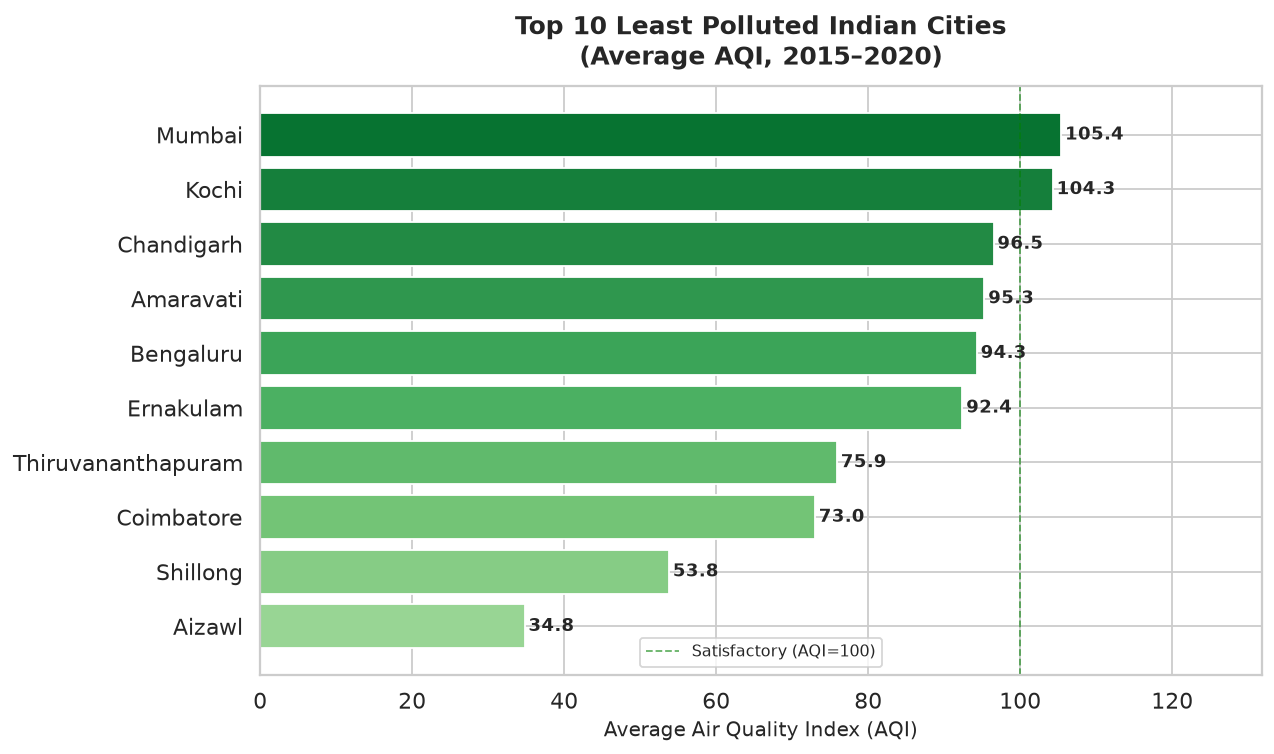

Least polluted city: Aizawl (avg AQI 34.8)
Interpretation: The cleanest cities are predominantly in northeast India and coastal south India.
Aizawl and Shillong have exceptionally low AQI due to minimal industrialisation,
high rainfall, and forest cover that filters airborne pollutants naturally.


In [21]:
bot10 = city_avg.tail(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.Greens(np.linspace(0.4, 0.85, len(bot10)))
bars = ax.barh(bot10.index, bot10.values, color=colors, edgecolor='white')

for bar, val in zip(bars, bot10.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Top 10 Least Polluted Indian Cities\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average Air Quality Index (AQI)', fontsize=11)
ax.set_xlim(0, bot10.max() * 1.25)

ax.axvline(100, color='green', linestyle='--', linewidth=1, alpha=0.6, label='Satisfactory (AQI=100)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'least_polluted_cities.png'))
plt.show()

print(f"Least polluted city: {city_avg.index[-1]} (avg AQI {city_avg.iloc[-1]})")
print("Interpretation: The cleanest cities are predominantly in northeast India and coastal south India.")
print("Aizawl and Shillong have exceptionally low AQI due to minimal industrialisation,")
print("high rainfall, and forest cover that filters airborne pollutants naturally.")

## Visualization 5 — Year-wise Average AQI Trend (Line Chart)

**What it shows:** Whether air quality improved or worsened between 2015 and 2020.  
Note: 2020 covers only January–July, so the lower value may partly reflect seasonal timing, not just improvement.

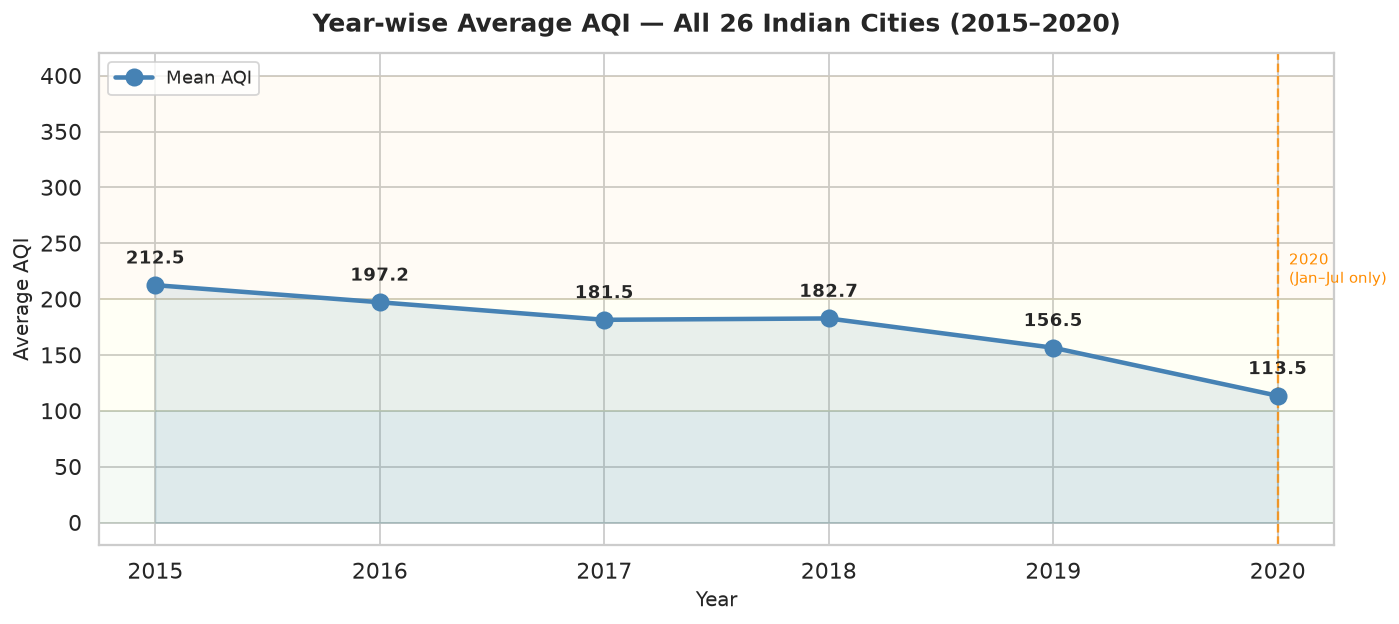

Interpretation: There is a general downward trend from 2015 to 2020.
However, 2020 must be interpreted cautiously — it covers only Jan–Jul
and the COVID-19 lockdown reduced industrial and vehicle emissions significantly.


In [22]:
year_avg = df.groupby('Year')['AQI'].mean().round(1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(year_avg.index, year_avg.values, marker='o', color='steelblue',
        linewidth=2.5, markersize=9, zorder=3, label='Mean AQI')
ax.fill_between(year_avg.index, year_avg.values, alpha=0.12, color='steelblue')

for yr, val in year_avg.items():
    ax.annotate(f'{val}', (yr, val), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=10, fontweight='bold')

# Mark 2020 as partial year
ax.axvline(2020, color='darkorange', linestyle='--', linewidth=1.3, alpha=0.8)
ax.text(2020.05, year_avg.max() * 1.01, '2020\n(Jan–Jul only)',
        fontsize=8.5, color='darkorange')

# AQI reference bands
ax.axhspan(0,   100, alpha=0.04, color='green')
ax.axhspan(100, 200, alpha=0.04, color='yellow')
ax.axhspan(200, 400, alpha=0.04, color='orange')

ax.set_title('Year-wise Average AQI — All 26 Indian Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Average AQI', fontsize=11)
ax.set_xticks(year_avg.index)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'yearly_aqi_trend.png'))
plt.show()

print("Interpretation: There is a general downward trend from 2015 to 2020.")
print("However, 2020 must be interpreted cautiously — it covers only Jan–Jul")
print("and the COVID-19 lockdown reduced industrial and vehicle emissions significantly.")

## Visualization 6 — Monthly Average AQI (Seasonal Pattern)

**What it shows:** How pollution levels change across the 12 calendar months — identifying the most dangerous and cleanest seasons.

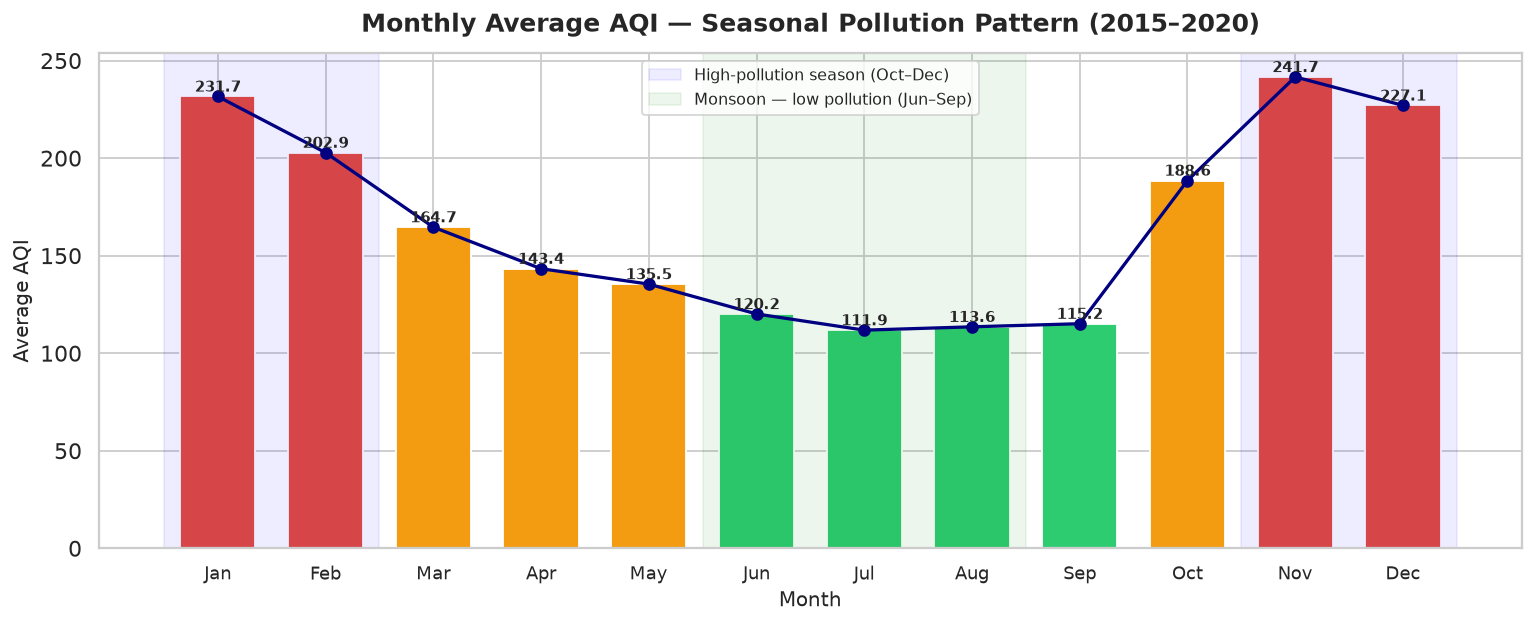

Peak month: November (241.7)
Lowest month: July (111.9)
Interpretation: Pollution peaks in winter (Nov–Jan) due to temperature inversions,
agricultural stubble burning, and reduced wind dispersal.
Monsoon months (Jun–Aug) show the lowest AQI as rain washes particles from the air.


In [23]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
month_short = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_avg   = df.groupby('Month')['AQI'].mean().reindex(month_order).round(1)

fig, ax = plt.subplots(figsize=(12, 5))

bar_colors = ['#e74c3c' if v > 200 else '#f39c12' if v > 130 else '#2ecc71'
              for v in month_avg.values]

bars = ax.bar(range(1, 13), month_avg.values, color=bar_colors, edgecolor='white', width=0.7)
ax.plot(range(1, 13), month_avg.values, marker='o', color='navy',
        linewidth=1.8, markersize=6, zorder=3)

for i, val in enumerate(month_avg.values):
    ax.text(i + 1, val + 2.5, f'{val}', ha='center', fontsize=8.5, fontweight='bold')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_short, fontsize=10)
ax.set_title('Monthly Average AQI — Seasonal Pollution Pattern (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Average AQI', fontsize=11)

# Annotate seasons
ax.axvspan(10.5, 12.5, alpha=0.07, color='blue', label='High-pollution season (Oct–Dec)')
ax.axvspan(0.5,  2.5,  alpha=0.07, color='blue')
ax.axvspan(5.5,  8.5,  alpha=0.07, color='green', label='Monsoon — low pollution (Jun–Sep)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'monthly_aqi_trend.png'))
plt.show()

print(f"Peak month: {month_avg.idxmax()} ({month_avg.max():.1f})")
print(f"Lowest month: {month_avg.idxmin()} ({month_avg.min():.1f})")
print("Interpretation: Pollution peaks in winter (Nov–Jan) due to temperature inversions,")
print("agricultural stubble burning, and reduced wind dispersal.")
print("Monsoon months (Jun–Aug) show the lowest AQI as rain washes particles from the air.")

## Visualization 7 — Pollutant Correlation Heatmap

**What it shows:** The strength of linear relationships between all pollutants and AQI.  
Values range from +1 (perfect positive correlation) to 0 (no correlation).  
> Reminder: Correlation shows association, not causation.

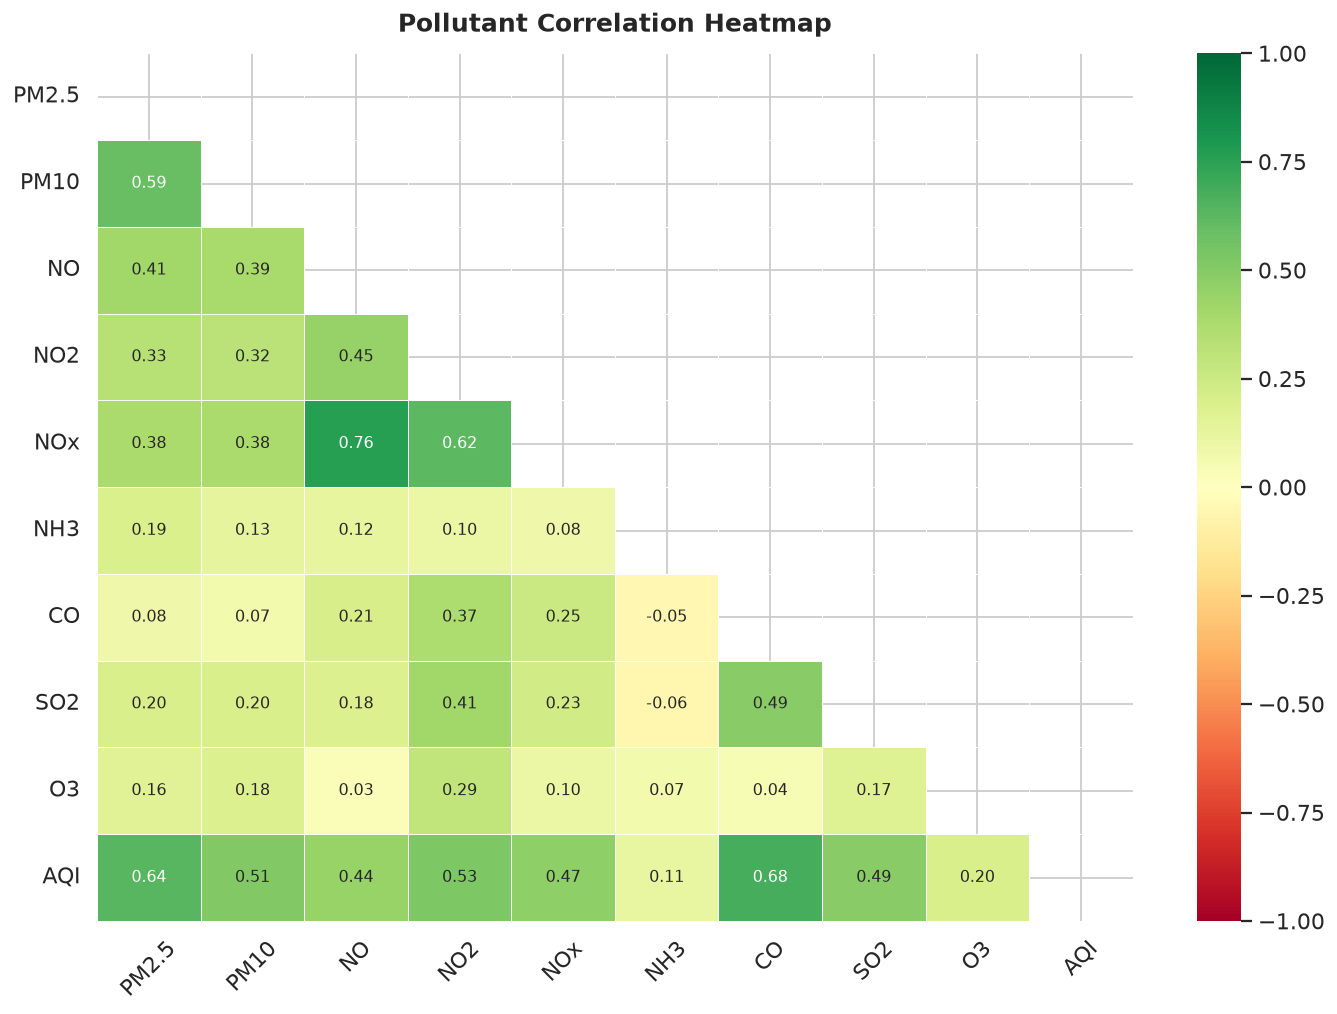

Correlation with AQI (strongest first):
  CO      : 0.680
  PM2.5   : 0.640
  NO2     : 0.530
  PM10    : 0.510
  SO2     : 0.490
  NOx     : 0.470
  NO      : 0.440
  O3      : 0.200
  NH3     : 0.110
Interpretation: PM2.5 and PM10 have the strongest positive correlation with AQI.
Particulate matter is the primary driver of the AQI score in Indian cities.


In [24]:
corr_cols   = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
corr_matrix = df[corr_cols].corr().round(2)

# Lower triangle mask
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 9}
)
ax.set_title('Pollutant Correlation Heatmap', fontsize=14, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_correlation_heatmap.png'))
plt.show()

aqi_corr = corr_matrix['AQI'].drop('AQI').sort_values(ascending=False)
print("Correlation with AQI (strongest first):")
for col, val in aqi_corr.items():
    print(f"  {col:<8}: {val:.3f}")
print("Interpretation: PM2.5 and PM10 have the strongest positive correlation with AQI.")
print("Particulate matter is the primary driver of the AQI score in Indian cities.")

## Visualization 8 — PM2.5 vs PM10 Scatter Plot

**What it shows:** The relationship between fine particles (PM2.5) and coarse particles (PM10), coloured by AQI level.

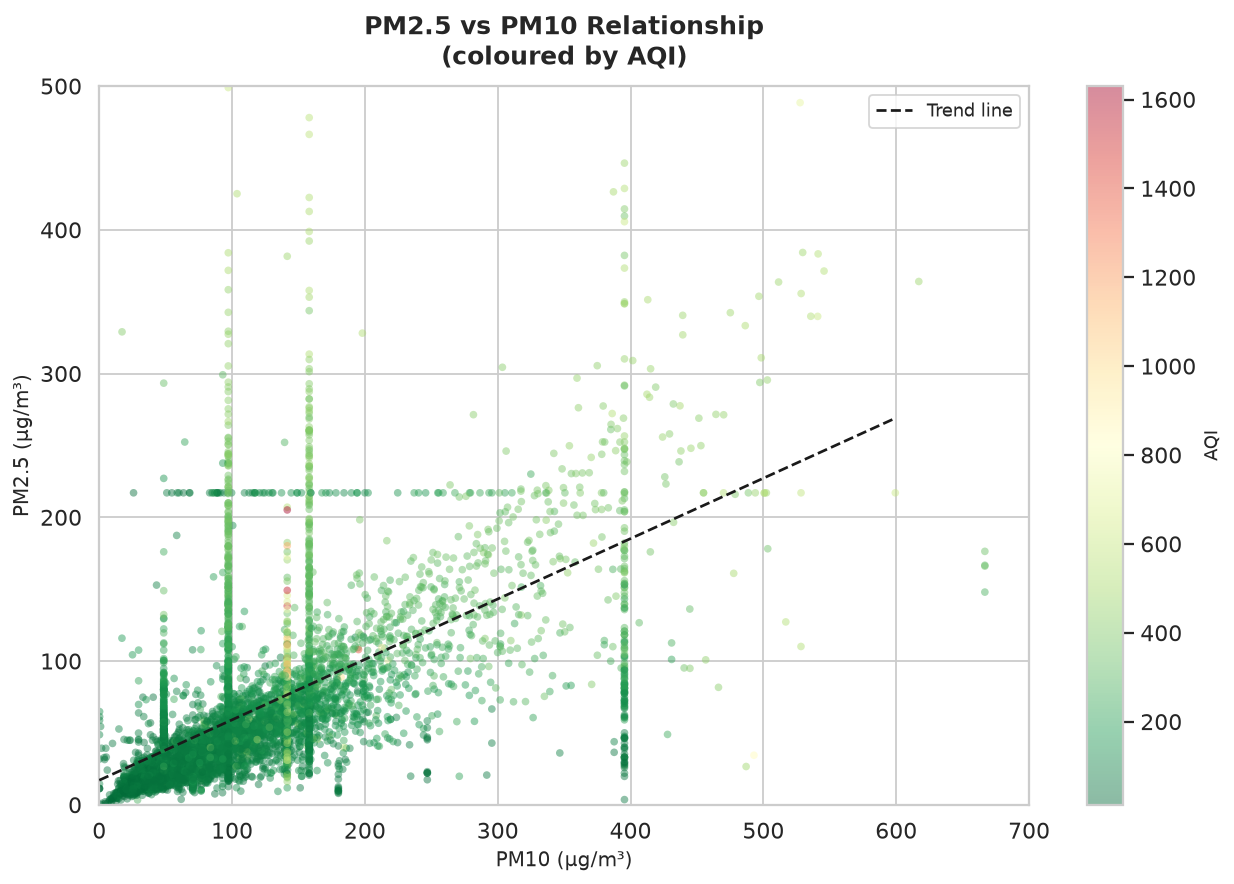

Pearson correlation PM2.5 vs PM10: 0.594
Interpretation: The strong positive correlation confirms PM2.5 and PM10 rise together.
Points coloured red (high AQI) are concentrated in the upper-right corner,
confirming both metrics drive AQI up. Some outliers have high PM10 but lower PM2.5,
which may indicate dust events (road dust, construction) rather than combustion sources.


In [25]:
sample = df.sample(n=min(6000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    sample['PM10'], sample['PM2.5'],
    c=sample['AQI'], cmap='RdYlGn_r',
    alpha=0.45, s=18, edgecolors='none'
)

# Trend line (clipped to avoid extreme outliers distorting the fit)
x_clip = sample['PM10'].clip(upper=600)
y_clip = sample['PM2.5'].clip(upper=400)
z = np.polyfit(x_clip, y_clip, 1)
p = np.poly1d(z)
x_line = np.linspace(0, 600, 300)
ax.plot(x_line, p(x_line), 'k--', linewidth=1.5, label='Trend line', zorder=4)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('AQI', fontsize=10)

ax.set_xlim(0, 700)
ax.set_ylim(0, 500)
ax.set_title('PM2.5 vs PM10 Relationship\n(coloured by AQI)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('PM10 (µg/m³)', fontsize=11)
ax.set_ylabel('PM2.5 (µg/m³)', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pm25_pm10_scatter.png'))
plt.show()

corr = df['PM2.5'].corr(df['PM10'])
print(f"Pearson correlation PM2.5 vs PM10: {corr:.3f}")
print("Interpretation: The strong positive correlation confirms PM2.5 and PM10 rise together.")
print("Points coloured red (high AQI) are concentrated in the upper-right corner,")
print("confirming both metrics drive AQI up. Some outliers have high PM10 but lower PM2.5,")
print("which may indicate dust events (road dust, construction) rather than combustion sources.")

## Visualization 9 — Pollutant Distribution Box Plots

**What it shows:** The median, spread (IQR), and outliers for each key pollutant.

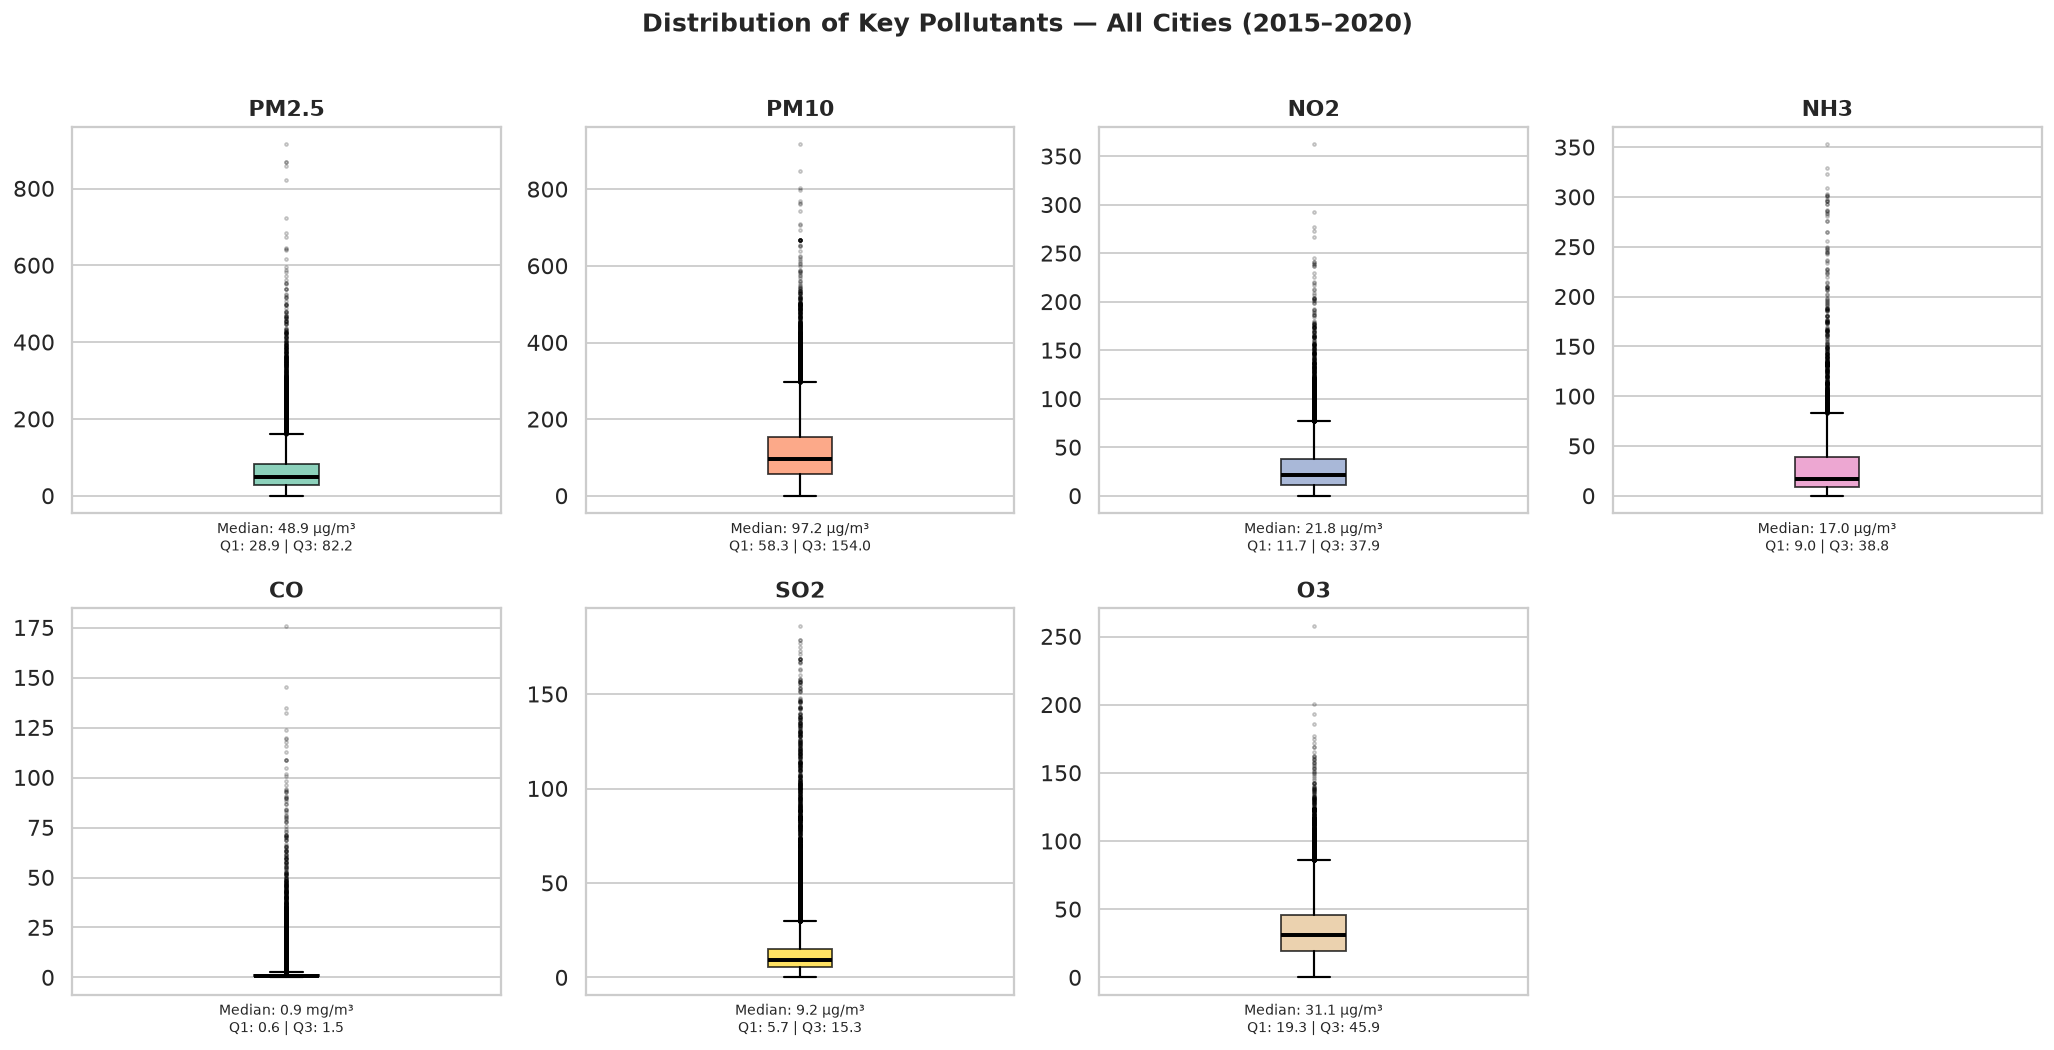

Interpretation: All pollutants are right-skewed with many high-value outliers,
confirming frequent episodic pollution events. PM10 has the highest median and
widest spread, while SO2 and O3 have lower typical concentrations.


In [26]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'CO', 'SO2', 'O3']
palette    = sns.color_palette('Set2', len(pollutants))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (pol, color) in enumerate(zip(pollutants, palette)):
    axes[i].boxplot(
        df[pol].dropna(),
        patch_artist=True,
        boxprops    =dict(facecolor=color, alpha=0.75),
        medianprops =dict(color='black', linewidth=2.2),
        whiskerprops=dict(linewidth=1.2),
        capprops    =dict(linewidth=1.2),
        flierprops  =dict(marker='o', markersize=1.5, alpha=0.25, color=color)
    )
    median_val = df[pol].median()
    q1 = df[pol].quantile(0.25)
    q3 = df[pol].quantile(0.75)
    unit = 'mg/m³' if pol == 'CO' else 'µg/m³'
    axes[i].set_title(pol, fontweight='bold', fontsize=12)
    axes[i].set_xlabel(f'Median: {median_val:.1f} {unit}\nQ1: {q1:.1f} | Q3: {q3:.1f}', fontsize=8)
    axes[i].set_xticks([])

axes[-1].set_visible(False)
fig.suptitle('Distribution of Key Pollutants — All Cities (2015–2020)', fontsize=14, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_boxplots.png'))
plt.show()

print("Interpretation: All pollutants are right-skewed with many high-value outliers,")
print("confirming frequent episodic pollution events. PM10 has the highest median and")
print("widest spread, while SO2 and O3 have lower typical concentrations.")

## Visualization 10 — City-wise Pollutant Comparison (Grouped Bar Chart)

**What it shows:** Average PM2.5, PM10, and NO2 concentrations for each city — identifying which pollutant dominates in which city.

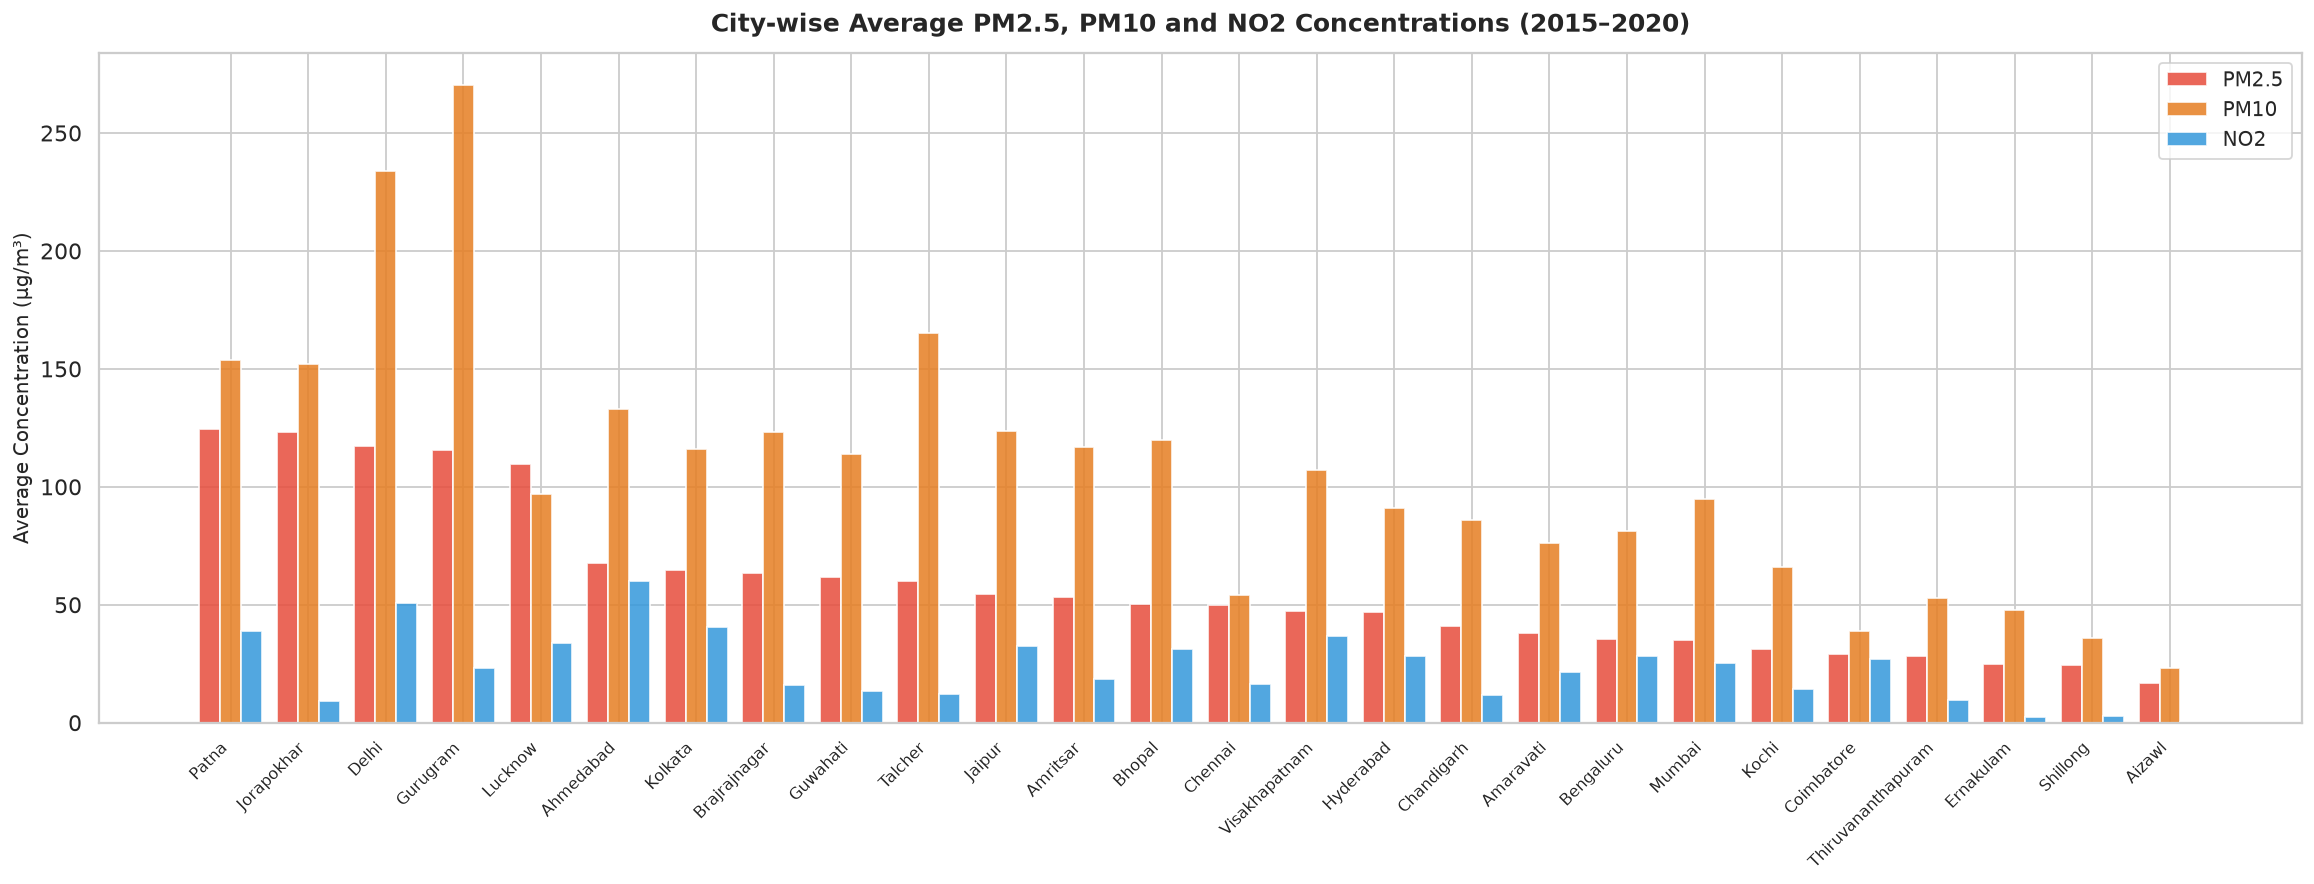

Interpretation: Cities like Delhi, Ahmedabad and Lucknow show high concentrations
across all three pollutants. Some cities have notably high PM10 relative to PM2.5,
suggesting dust (roads, construction) is a major local source.
NO2 is highest in Delhi, reflecting its dense and high-emission vehicle fleet.


In [27]:
city_poll = df.groupby('City')[['PM2.5', 'PM10', 'NO2']].mean().sort_values('PM2.5', ascending=False).round(1)

x     = np.arange(len(city_poll))
width = 0.27

fig, ax = plt.subplots(figsize=(18, 7))

ax.bar(x - width, city_poll['PM2.5'], width, label='PM2.5', color='#e74c3c', alpha=0.85, edgecolor='white')
ax.bar(x,          city_poll['PM10'],  width, label='PM10',  color='#e67e22', alpha=0.85, edgecolor='white')
ax.bar(x + width, city_poll['NO2'],   width, label='NO2',   color='#3498db', alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(city_poll.index, rotation=45, ha='right', fontsize=9)
ax.set_title('City-wise Average PM2.5, PM10 and NO2 Concentrations (2015–2020)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Average Concentration (µg/m³)', fontsize=11)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'city_pollutant_comparison.png'))
plt.show()

# Save data table
city_poll.to_csv(os.path.join(TABLE_DIR, 'city_pollutant_averages.csv'))
print("Interpretation: Cities like Delhi, Ahmedabad and Lucknow show high concentrations")
print("across all three pollutants. Some cities have notably high PM10 relative to PM2.5,")
print("suggesting dust (roads, construction) is a major local source.")
print("NO2 is highest in Delhi, reflecting its dense and high-emission vehicle fleet.")

---
# Section 8 — Findings and Observations

These findings are computed directly from the dataset, not assumed in advance.

In [28]:
city_avg   = df.groupby('City')['AQI'].mean().sort_values(ascending=False)
year_avg   = df.groupby('Year')['AQI'].mean()
month_avg  = df.groupby('Month')['AQI'].mean().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December'])
cat_counts = df['AQI_Bucket'].value_counts()
pm_corr    = df[['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','AQI']].corr()['AQI'].drop('AQI')

print("=" * 65)
print("COMPUTED FINDINGS FROM THE ANALYSIS")
print("=" * 65)

print(f"\n1. MOST POLLUTED CITY   : {city_avg.index[0]} (avg AQI {city_avg.iloc[0]:.1f})")
print(f"   LEAST POLLUTED CITY  : {city_avg.index[-1]} (avg AQI {city_avg.iloc[-1]:.1f})")
print(f"   AQI gap (max - min)  : {city_avg.iloc[0] - city_avg.iloc[-1]:.1f} units")

print(f"\n2. AQI TREND 2015→2020  : {year_avg[2015]:.1f} → {year_avg[2019]:.1f} (2015–2019, complete years)")
direction = 'Improvement' if year_avg[2015] > year_avg[2019] else 'Worsening'
print(f"   Direction            : {direction}")

print(f"\n3. PEAK POLLUTION MONTH  : {month_avg.idxmax()} (avg AQI {month_avg.max():.1f})")
print(f"   LOWEST POLLUTION MONTH: {month_avg.idxmin()} (avg AQI {month_avg.min():.1f})")

print(f"\n4. AQI CATEGORY BREAKDOWN:")
for cat in ['Good','Satisfactory','Moderate','Poor','Very Poor','Severe']:
    if cat in cat_counts.index:
        pct = cat_counts[cat] / len(df) * 100
        print(f"   {cat:<15s}: {cat_counts[cat]:5,} days ({pct:.1f}%)")

print(f"\n5. STRONGEST POLLUTANT CORRELATIONS WITH AQI:")
for col, val in pm_corr.abs().sort_values(ascending=False).head(3).items():
    actual_val = pm_corr[col]
    print(f"   {col:<8}: r = {actual_val:.3f}")

print(f"\n6. PM2.5 vs PM10 CORRELATION: r = {df['PM2.5'].corr(df['PM10']):.3f}")

poor_pct = (df['AQI'] > 200).sum() / len(df) * 100
print(f"\n7. RECORDS WITH AQI > 200 (Poor or worse): {(df['AQI']>200).sum():,} ({poor_pct:.1f}% of all city-days)")

extreme_city = df[df['AQI'] > 500]['City'].value_counts().head(3)
print(f"\n8. CITIES WITH MOST AQI > 500 RECORDS:")
for city, cnt in extreme_city.items():
    print(f"   {city}: {cnt} days")

COMPUTED FINDINGS FROM THE ANALYSIS

1. MOST POLLUTED CITY   : Ahmedabad (avg AQI 452.1)
   LEAST POLLUTED CITY  : Aizawl (avg AQI 34.8)
   AQI gap (max - min)  : 417.4 units

2. AQI TREND 2015→2020  : 212.5 → 156.5 (2015–2019, complete years)
   Direction            : Improvement

3. PEAK POLLUTION MONTH  : November (avg AQI 241.7)
   LOWEST POLLUTION MONTH: July (avg AQI 111.9)

4. AQI CATEGORY BREAKDOWN:
   Good           : 1,341 days (5.4%)
   Satisfactory   : 8,224 days (33.1%)
   Moderate       : 8,829 days (35.5%)
   Poor           : 2,781 days (11.2%)
   Very Poor      : 2,337 days (9.4%)
   Severe         : 1,338 days (5.4%)

5. STRONGEST POLLUTANT CORRELATIONS WITH AQI:
   CO      : r = 0.678
   PM2.5   : r = 0.635
   NO2     : r = 0.533

6. PM2.5 vs PM10 CORRELATION: r = 0.594

7. RECORDS WITH AQI > 200 (Poor or worse): 6,456 (26.0% of all city-days)

8. CITIES WITH MOST AQI > 500 RECORDS:
   Ahmedabad: 412 days
   Delhi: 48 days
   Patna: 25 days


---
# Section 9 — Limitations

No dataset or analysis is perfect. These are the key limitations you should acknowledge:

**1. Missing data imputation limitation**  
Forward fill and backward fill were used to fill pollutant readings for days when the sensor had no data. This carries the last known reading forward across consecutive missing days. If a station was offline for weeks, all those days receive the same imputed value — which does not represent actual conditions on those days. These imputed readings should not be treated as real measurements.

**2. Incomplete 2020 data**  
The dataset covers only January–July 2020. The apparent drop in AQI for 2020 is therefore not comparable with full-year data from 2015–2019. Part of the apparent improvement in 2020 is likely due to the COVID-19 national lockdown (March–May 2020), which significantly reduced vehicle traffic and industrial activity.

**3. Single monitoring station per city**  
Each city in this dataset is represented by one monitoring station. Large cities like Delhi have many different pollution levels across different zones. A single station may not reflect the air quality experienced by all residents in that city.

**4. Only 26 cities**  
India has hundreds of cities. This dataset covers only 26, so the results cannot be extended to represent all of urban India.

**5. Correlation does not imply causation**  
The correlation heatmap shows statistical associations between pollutants and AQI. This does not prove that one pollutant causes changes in another. Multiple environmental variables — temperature, wind speed, rainfall, local industry — influence pollution simultaneously.

**6. Suspicious PM10 < PM2.5 values**  
The data quality check found 2,757 records where PM10 is lower than PM2.5, which is physically impossible (PM2.5 is a subset of PM10). These likely result from imputation errors when PM10 and PM2.5 were filled from different reference points. These records were retained but flagged.

---
# Section 10 — Conclusion

This analysis of 24,850 city-day records from 26 Indian cities (2015–2020) provides clear evidence of a persistent and unequal air quality crisis in urban India.

**Key conclusions:**

- **Particulate matter is the dominant problem.** PM2.5 and PM10 have the strongest correlations with AQI and are the primary drivers of the Air Quality Index score across Indian cities.

- **Inequality in air quality is extreme.** The most polluted city has an average AQI roughly 10–15 times higher than the least polluted city. Geography, industrialisation, and local policy all shape the air quality experienced by residents.

- **Winter is the most dangerous season.** November, December, and January consistently show the highest average AQI due to temperature inversions, agricultural burning, and reduced wind dispersal.

- **There is a gradual improvement trend.** From 2015 to 2019, average AQI across all cities showed a downward trend. This may reflect stricter emission standards, cleaner fuel policies, and monitoring improvements.

- **Most days still exceed safe levels.** Even after improvement, only a small fraction of city-day records fall in the 'Good' category. The majority of urban Indians still face Moderate to Poor air quality on a typical day.

**Relevance to SDG 11:**  
These findings directly support SDG 11 Target 11.6. The data shows that targeted interventions — emission standards for vehicles, industrial controls, management of agricultural burning, and urban green cover — are needed in specific cities and seasons. Data-driven identification of the worst months and cities is essential for effective policy.

---
*Analysis completed using Python, pandas, matplotlib, and seaborn.*